# 3. Interferometro ciclico: visibilita' e conteggi

Notebook a corredo delle sezioni 7 e 8 della tesina.

Quattro modi, quattro beam splitter bilanciati connessi ad anello e una sola fase
$\varphi$ sul ramo alto del primo blocco. Con l'ingresso $|1,0,1,0\rangle$ le coincidenze
in cui un fotone emerge da C e uno da D dipendono da $\varphi$, benche' i due fotoni non si
incontrino mai nello stesso componente.

Il notebook percorre tre passaggi: le probabilita' esatte al variare della visibilita', il
campionamento poissoniano che simula un numero finito di eventi, e la stima della
visibilita' dai conteggi mediante un fit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.components import BS, PS, PERM

print("Perceval", pcvl.__version__)

Perceval 1.3.1


## 3.1 Il circuito

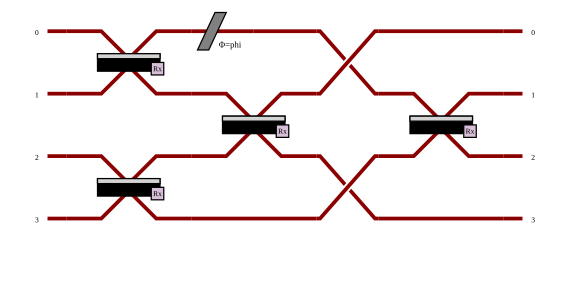

In [2]:
phi = pcvl.P("phi")

c = pcvl.Circuit(4)
c.add(0, BS())                  # blocco A: ingressi 1-2
c.add(2, BS())                  # blocco B: ingressi 3-4
c.add(0, PS(phi))               # la fase, sul ramo alto di A
c.add(1, BS())                  # blocco C
c.add(0, PERM([1, 0, 3, 2]))    # le uscite di C vanno ai modi esterni
c.add(1, BS())                  # blocco D

pcvl.pdisplay(c)

## 3.2 Gli stati interni e la visibilita'

I due fotoni portano uno stato interno, rappresentato in Perceval dalle annotazioni `{0}` e
`{1}`, che fungono da base ortonormale in luogo di $\{|H\rangle, |V\rangle\}$. Il primo
fotone e' fissato nello stato $|\{1\}\rangle$; il secondo e' una sovrapposizione il cui
peso si fa variare, ottenendo cosi' una visibilita'

$$V = \bigl|\langle\psi|\varphi\rangle\bigr|^2$$

che percorre l'intero intervallo da $0$ a $1$.

In [3]:
H = pcvl.BasicState("|{0}>")
V = pcvl.BasicState("|{1}>")

# primo fotone: interamente nello stato {1}
a_H, a_V = 0.0, 1.0
stato_1 = a_H * H + a_V * V

# secondo fotone: sovrapposizione a peso variabile
b_H = np.linspace(0, 1, 6)
b_V = np.sqrt(1 - b_H**2)

VIS = np.abs(np.conjugate(a_H) * b_H + np.conjugate(a_V) * b_V)**2

for bh, bv, v in zip(b_H, b_V, VIS):
    print(f"  b_H = {bh:.3f}   b_V = {bv:.3f}   V = {v:.4f}")

  b_H = 0.000   b_V = 1.000   V = 1.0000
  b_H = 0.200   b_V = 0.980   V = 0.9600
  b_H = 0.400   b_V = 0.917   V = 0.8400
  b_H = 0.600   b_V = 0.800   V = 0.6400
  b_H = 0.800   b_V = 0.600   V = 0.3600
  b_H = 1.000   b_V = 0.000   V = 0.0000


## 3.3 Le probabilita' esatte

Si calcolano le quattro coincidenze a blocchi distinti per ogni valore della fase e per ogni
valore della visibilita'.

Il simulatore dipende dal solo circuito, e dunque dalla sola fase: conviene percio'
costruirlo una volta per ciascun valore di $\varphi$ e riusarlo per tutte le visibilita',
anziche' ricostruirlo nel ciclo piu' interno.

In [4]:
uscite = {"P12": pcvl.BasicState([1, 1, 0, 0]),
          "P13": pcvl.BasicState([1, 0, 1, 0]),
          "P42": pcvl.BasicState([0, 1, 0, 1]),
          "P43": pcvl.BasicState([0, 0, 1, 1])}

valori_phi = np.linspace(0, 2*np.pi, 200)

# stato di ingresso per ciascuna visibilita': un fotone nel modo 1 e uno nel modo 3
ingressi = []
for bh, bv in zip(b_H, b_V):
    stato_2 = float(bh) * H + float(bv) * V
    ingressi.append(stato_1 * pcvl.BasicState("|0>") * stato_2 * pcvl.BasicState("|0>"))

# probabilita[nome][i_visibilita, i_fase]
probabilita = {nome: np.zeros((len(b_H), len(valori_phi))) for nome in uscite}

for j, f in enumerate(valori_phi):
    phi.set_value(float(f))
    simulatore = pcvl.SimulatorFactory().build(pcvl.Processor("Naive", c))
    for i, ingresso in enumerate(ingressi):
        for nome, uscita in uscite.items():
            probabilita[nome][i, j] = simulatore.probability(ingresso, uscita)

print("calcolo completato:", probabilita["P12"].shape)

calcolo completato: (6, 200)


In [5]:
# verifica: a visibilita' unitaria devono valere le formule della sezione 7.3
atteso_12 = (1 - np.cos(valori_phi)) / 8
atteso_13 = (1 + np.cos(valori_phi)) / 8
i_uno = int(np.argmax(VIS))

print(f"  V = {VIS[i_uno]:.3f}")
print(f"  scarto su P12 rispetto a (1-cos phi)/8: {np.max(np.abs(probabilita['P12'][i_uno] - atteso_12)):.2e}")
print(f"  scarto su P13 rispetto a (1+cos phi)/8: {np.max(np.abs(probabilita['P13'][i_uno] - atteso_13)):.2e}")

  V = 1.000
  scarto su P12 rispetto a (1-cos phi)/8: 8.33e-17
  scarto su P13 rispetto a (1+cos phi)/8: 1.11e-16


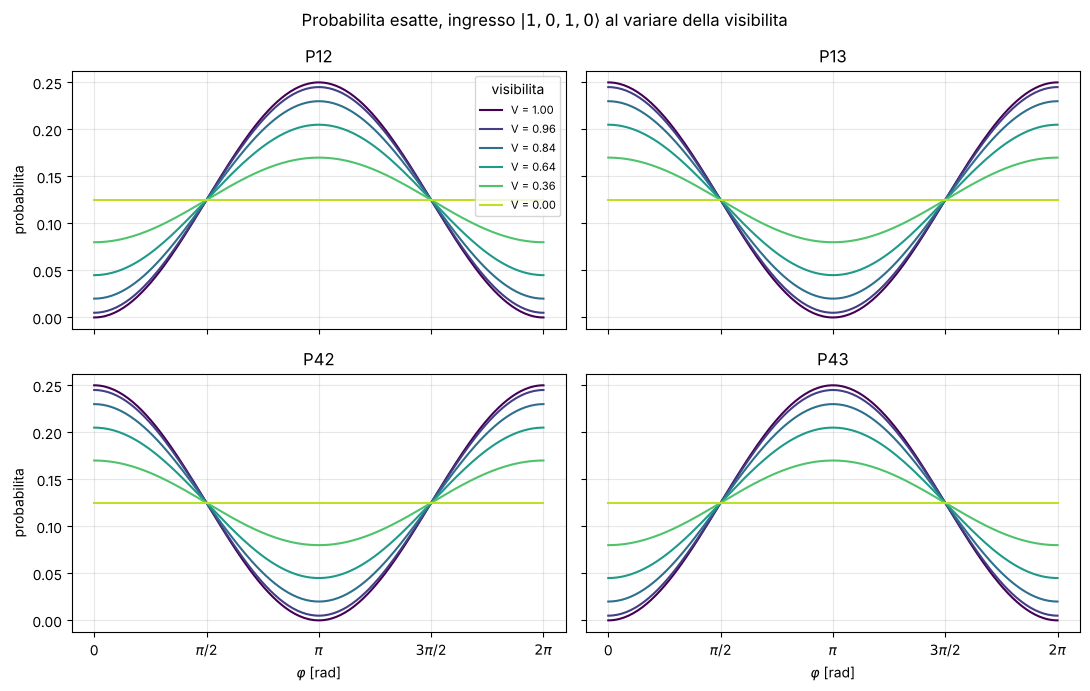

In [6]:
colori = plt.cm.viridis(np.linspace(0, 0.9, len(b_H)))

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

for ax, nome in zip(axes.flat, uscite):
    for i, vis in enumerate(VIS):
        ax.plot(valori_phi, probabilita[nome][i], "-", color=colori[i], label=f"V = {vis:.2f}")
    ax.set_title(nome)
    ax.grid(alpha=0.3)
    ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax.set_xticklabels(["0", r"$\pi$/2", r"$\pi$", r"$3\pi$/2", r"$2\pi$"])

for ax in axes[1]:
    ax.set_xlabel(r"$\varphi$ [rad]")
for ax in axes[:, 0]:
    ax.set_ylabel("probabilita")

axes[0, 0].legend(title="visibilita", fontsize=8)
fig.suptitle(r"Probabilita esatte, ingresso $|1,0,1,0\rangle$ al variare della visibilita")
plt.tight_layout()
plt.show()

## 3.4 Campionamento poissoniano

In un esperimento la sorgente e' impulsata e ciascun tentativo produce l'esito cercato con
probabilita' molto ridotta: i conteggi seguono percio' una distribuzione di Poisson di media
$\lambda = pN$. Si estrae il campione e si ricostruisce la probabilita' come $c/N$, con
incertezza $\sqrt{c}/N$.

In [7]:
N_EVENTI = 1000
rng = np.random.default_rng(1)

conteggi  = {nome: rng.poisson(probabilita[nome] * N_EVENTI) for nome in uscite}
p_stimata = {nome: conteggi[nome] / N_EVENTI for nome in uscite}
sigma     = {nome: np.sqrt(conteggi[nome]) / N_EVENTI for nome in uscite}

# copertura della barra a un sigma: ci si attende circa il 68%
dentro = np.mean([np.abs(p_stimata[n] - probabilita[n]) <= sigma[n] for n in uscite])
print(f"frazione di punti entro una deviazione standard: {dentro:.3f}")

frazione di punti entro una deviazione standard: 0.677


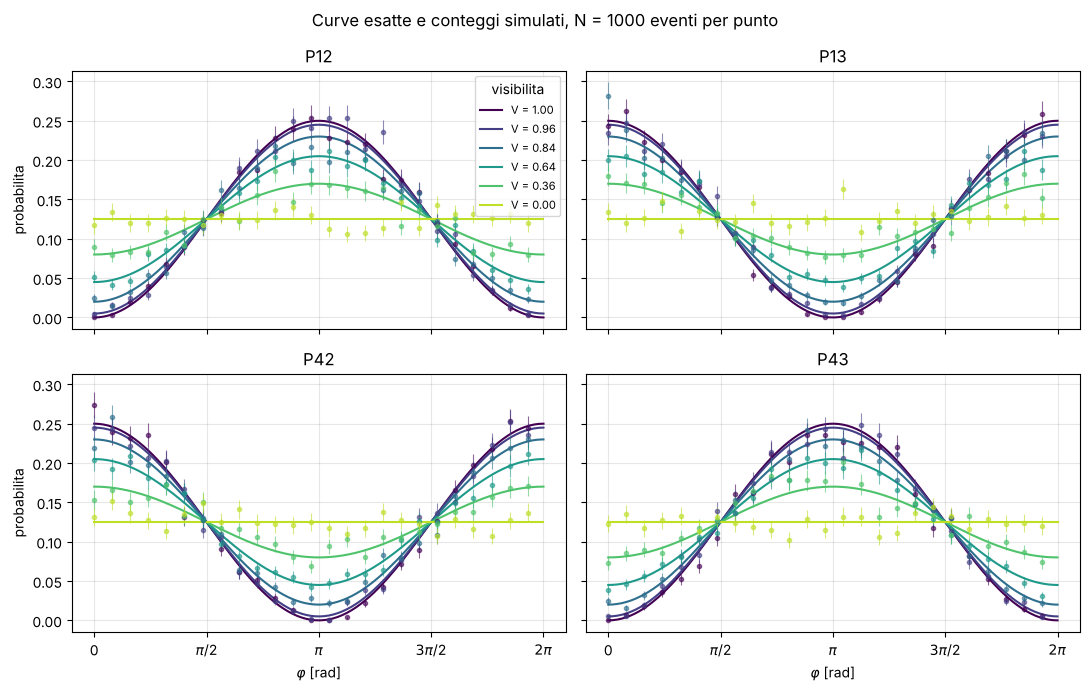

In [8]:
passo = 8   # si disegna un punto ogni 'passo' per non affollare il grafico

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

for ax, nome in zip(axes.flat, uscite):
    for i, vis in enumerate(VIS):
        ax.plot(valori_phi, probabilita[nome][i], "-", color=colori[i], label=f"V = {vis:.2f}")
        ax.errorbar(valori_phi[::passo], p_stimata[nome][i][::passo],
                    yerr=sigma[nome][i][::passo], fmt="o", ms=3, lw=0.8,
                    alpha=0.6, color=colori[i])
    ax.set_title(nome)
    ax.grid(alpha=0.3)
    ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax.set_xticklabels(["0", r"$\pi$/2", r"$\pi$", r"$3\pi$/2", r"$2\pi$"])

for ax in axes[1]:
    ax.set_xlabel(r"$\varphi$ [rad]")
for ax in axes[:, 0]:
    ax.set_ylabel("probabilita")

axes[0, 0].legend(title="visibilita", fontsize=8)
fig.suptitle(f"Curve esatte e conteggi simulati, N = {N_EVENTI} eventi per punto")
plt.tight_layout()
plt.show()

## 3.5 Stima della visibilita' dai conteggi

La dipendenza dalla fase e' lineare in $\cos\varphi$,

$$\hat p(\varphi) = a - b\cos\varphi ,
  \qquad V = \frac{b}{a} ,$$

sicche' i due coefficienti si ricavano con un minimo quadrato lineare la cui matrice di
disegno ha per colonne il vettore unitario e $-\cos\varphi$. Rispetto alla definizione che
impiega il solo massimo e il solo minimo, il fit usa tutti i punti della curva e risulta
percio' meno sensibile al rumore sui valori estremi.

In [9]:
def stima_visibilita(p):
    """Minimo quadrato lineare su p(phi) = a - b cos(phi); restituisce V = b/a."""
    A = np.column_stack([np.ones_like(valori_phi), -np.cos(valori_phi)])
    (a, b), *_ = np.linalg.lstsq(A, p, rcond=None)
    return b / a

print(f"{'V vera':>10} {'V stimata':>12} {'scarto':>10}")
for i, vera in enumerate(VIS):
    stimata = stima_visibilita(p_stimata["P12"][i])
    print(f"{vera:10.4f} {stimata:12.4f} {stimata - vera:+10.4f}")

    V vera    V stimata     scarto
    1.0000       0.9931    -0.0069
    0.9600       0.9571    -0.0029
    0.8400       0.8276    -0.0124
    0.6400       0.6476    +0.0076
    0.3600       0.3663    +0.0063
    0.0000      -0.0010    -0.0010


## 3.6 Come decresce l'incertezza

L'errore relativo di una poissoniana vale $1/\sqrt{\lambda}$, sicche' quadruplicare il
tempo di acquisizione dimezza l'incertezza. Si ripete allora la stima della visibilita' al
crescere del numero di eventi per punto, su piu' realizzazioni indipendenti.

In [10]:
i_prova = int(np.argmin(np.abs(VIS - 0.75)))   # una visibilita' intermedia
vera = VIS[i_prova]
p_vera = probabilita["P12"][i_prova]

print(f"visibilita' vera: {vera:.4f}\n")
print(f"{'N eventi':>10} {'media':>10} {'dev. std':>12}")
for N in [100, 1000, 10000, 100000]:
    stime = []
    for ripetizione in range(40):
        g = np.random.default_rng(1000 * ripetizione + N)
        stime.append(stima_visibilita(g.poisson(p_vera * N) / N))
    print(f"{N:10d} {np.mean(stime):10.4f} {np.std(stime):12.4f}")

visibilita' vera: 0.8400

  N eventi      media     dev. std
       100     0.8397       0.0300
      1000     0.8393       0.0064
     10000     0.8399       0.0022
    100000     0.8400       0.0007
